In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from grader_contracts.pandas_tasks import TitanicInput
from grader_contracts.correlation_tasks import BrainDataInput
from pandas_tasks import analyze_titanic
from correlation_tasks import analyze_brain_correlations

sns.set_theme(style="whitegrid")

## Часть 1. Titanic и Pandas

In [2]:
result = analyze_titanic(TitanicInput("titanic.csv"))
result

TitanicSummary(row_count=891, missing_by_column={'PassengerId': 0, 'Survived': 0, 'Pclass': 0, 'Name': 0, 'Sex': 0, 'Age': 177, 'SibSp': 0, 'Parch': 0, 'Ticket': 0, 'Fare': 0, 'Cabin': 687, 'Embarked': 2}, adults_over_30_count=305, mean_age_by_pclass={1: 38.233440860215055, 2: 29.87763005780347, 3: 25.14061971830986}, survival_rate_by_pclass={1: 0.6296296296296297, 2: 0.47282608695652173, 3: 0.24236252545824846}, highest_fares=[512.3292, 512.3292, 512.3292, 263.0, 263.0])

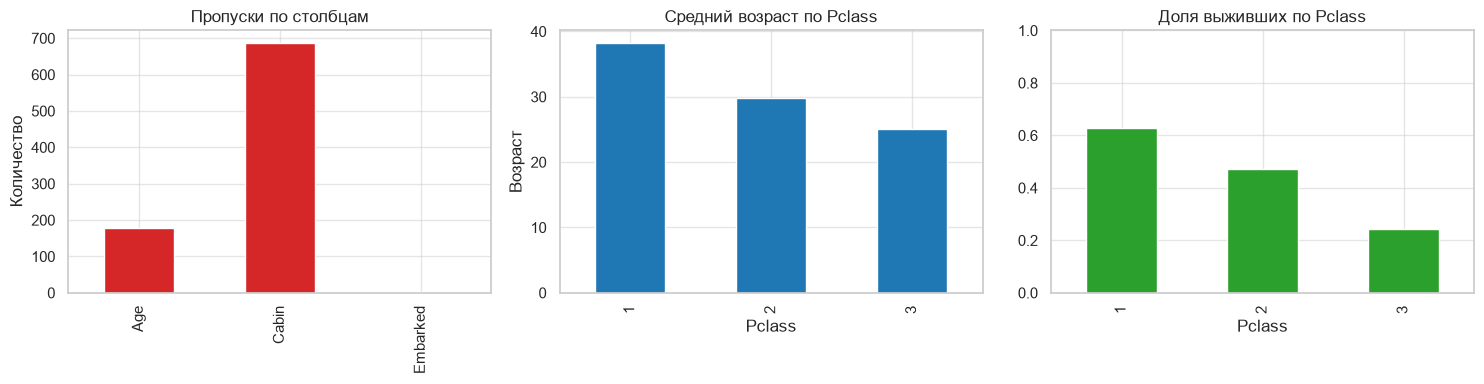

In [3]:
titanic = pd.read_csv("titanic.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# пропуски по столбцам (только там, где они есть)
miss = pd.Series(result.missing_by_column)
miss = miss[miss > 0]
miss.plot(kind="bar", ax=axes[0], color="tab:red")
axes[0].set_title("Пропуски по столбцам")
axes[0].set_ylabel("Количество")

# средний возраст по классам
pd.Series(result.mean_age_by_pclass).plot(kind="bar", ax=axes[1], color="tab:blue")
axes[1].set_title("Средний возраст по Pclass")
axes[1].set_xlabel("Pclass")
axes[1].set_ylabel("Возраст")

# доля выживших по классам
pd.Series(result.survival_rate_by_pclass).plot(kind="bar", ax=axes[2], color="tab:green")
axes[2].set_title("Доля выживших по Pclass")
axes[2].set_xlabel("Pclass")
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

**Выводы.** Больше всего пропусков в `Cabin` (687), затем в `Age` (177); пропуски возраста не заменялись нулём, а игнорировались при расчёте среднего. Чем выше класс, тем старше пассажиры и тем выше доля выживших (1 класс: ~0.63, 3 класс: ~0.24).

## Часть 2. Корреляционный анализ (brainsize.txt)

In [4]:
brain_result = analyze_brain_correlations(BrainDataInput("brainsize.txt"))
brain_result

BrainCorrelationSummary(men_count=20, women_count=20, women_mri_correlation={'FSIQ': 0.3256967004963704, 'VIQ': 0.25493285296147655, 'PIQ': 0.3961571668684764, 'Weight': 0.446271352661643, 'Height': 0.17454104728809813}, men_mri_correlation={'FSIQ': 0.4983691104171926, 'VIQ': 0.4131049601428285, 'PIQ': 0.5682370032144157, 'Weight': -0.0768746437133317, 'Height': 0.3015430401770577}, strongest_mri_feature='PIQ')

In [5]:
brain = pd.read_csv("brainsize.txt", sep="\t", na_values="NA")
features = ["FSIQ", "VIQ", "PIQ", "Weight", "Height"]
men = brain[brain["Gender"] == "Male"]
women = brain[brain["Gender"] == "Female"]

corr_table = pd.DataFrame({
    "Женщины": brain_result.women_mri_correlation,
    "Мужчины": brain_result.men_mri_correlation,
})
corr_table

,Женщины,Мужчины
FSIQ,0.325697,0.498369
VIQ,0.254933,0.413105
PIQ,0.396157,0.568237
Weight,0.446271,-0.076875
Height,0.174541,0.301543


### Scatter-графики: признак против MRI_Count

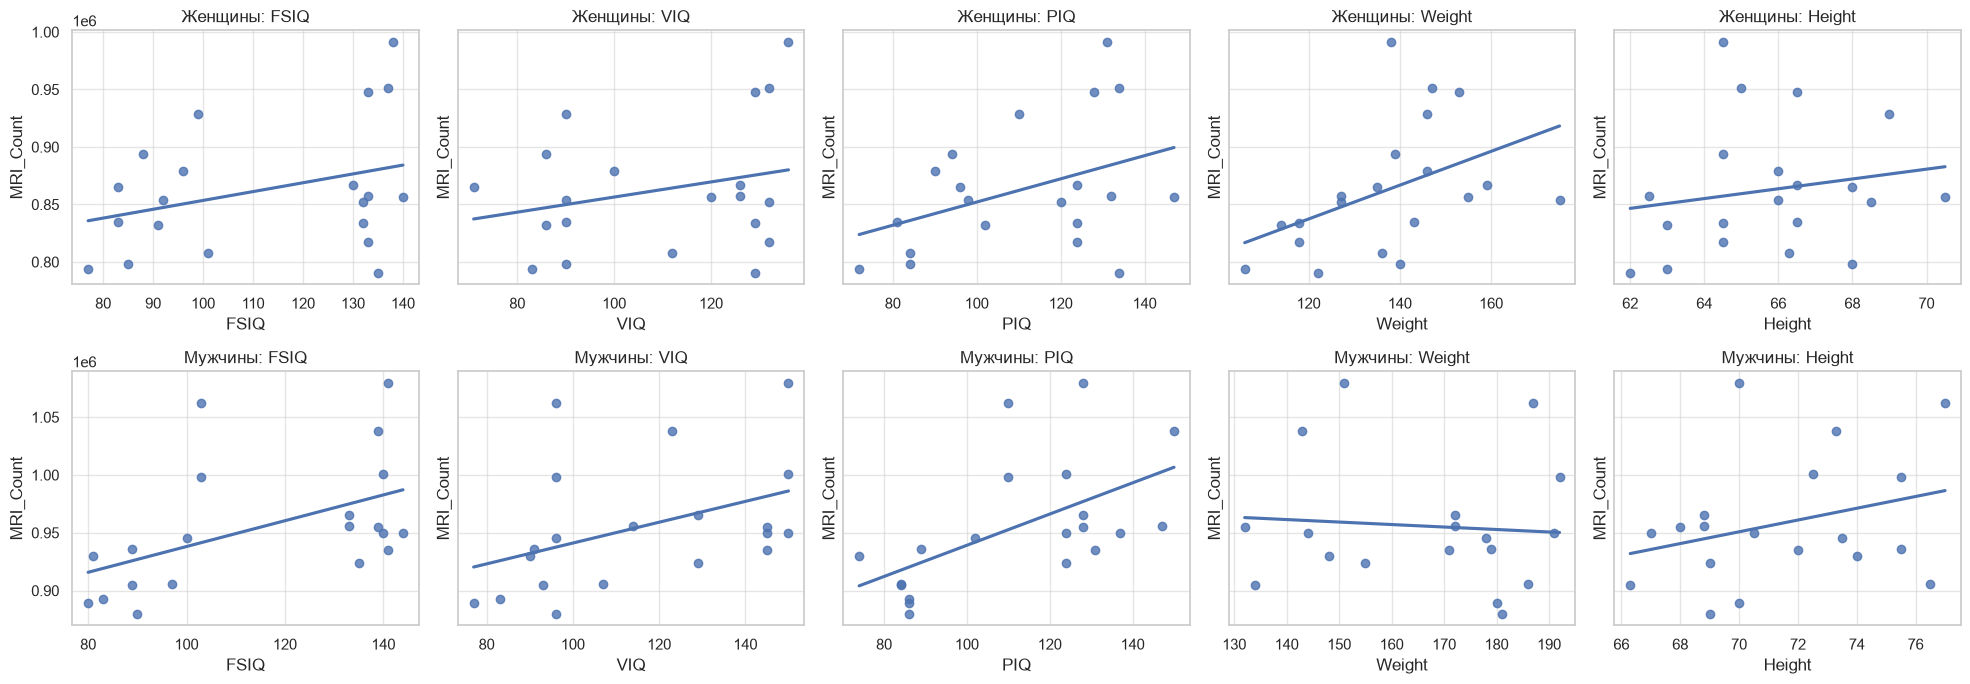

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharey="row")
for row, (name, group) in enumerate([("Женщины", women), ("Мужчины", men)]):
    for col, feature in enumerate(features):
        ax = axes[row, col]
        sns.regplot(data=group, x=feature, y="MRI_Count", ax=ax, ci=None)
        ax.set_title(f"{name}: {feature}")
plt.tight_layout()
plt.show()

### Heatmap корреляций

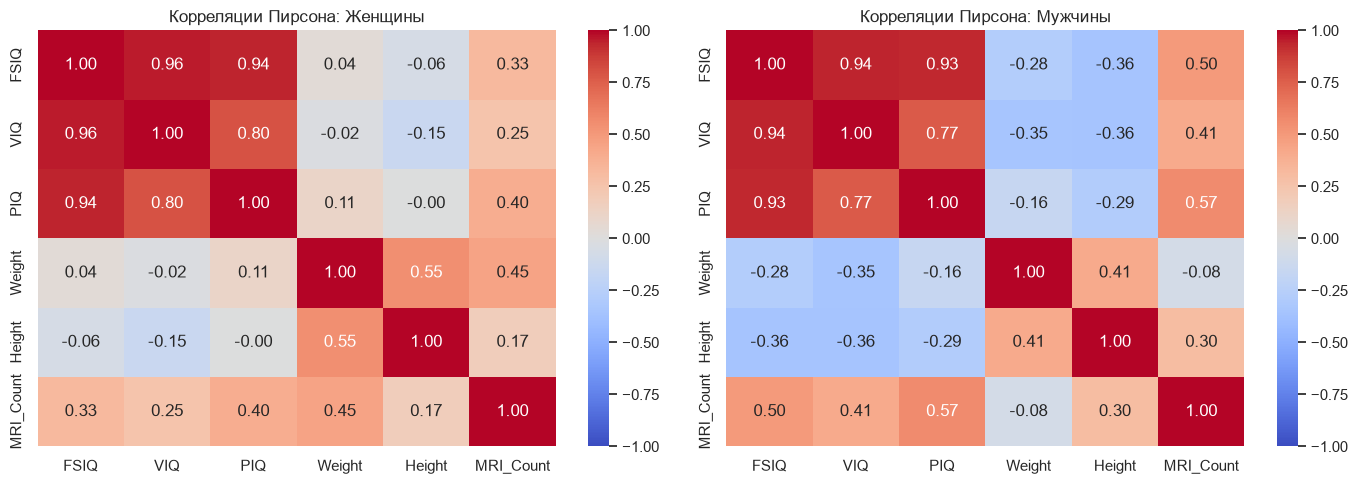

In [7]:
cols = features + ["MRI_Count"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, group) in zip(axes, [("Женщины", women), ("Мужчины", men)]):
    sns.heatmap(group[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"Корреляции Пирсона: {name}")
plt.tight_layout()
plt.show()

**Вывод.** Среди обеих групп максимальный модуль корреляции с `MRI_Count` у признака, записанного в `strongest_mri_feature` (у мужчин `PIQ` ≈ 0.57). У женщин самый сильный признак - `Weight` (≈ 0.45), а у мужчин вес практически не связан с объёмом мозга (≈ -0.08). Корреляция не означает причинно-следственную связь, а выборки маленькие (по 20 наблюдений).